**Manifold hypothesis, t-SNE, UMAP, and embedding validation**
-

**Libraries**
-

In [2]:
from pathlib import Path
import sys
from IPython.display import display

# Locate the project package from the project or notebooks folder.
project_root = Path.cwd().resolve()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.manifolds import ManifoldData, TSNESearch, UMAPSearch, FullEmbedding
from src.evaluation.manifolds import PreservationEvaluation, SeedStability
from src.models.manifold_plots import (
    plot_preservation, plot_seed_stability, plot_embedding, plot_categorical_segments,
)


## **1. Question of Interest**

### **1.2 Question**

- How effectively do t-SNE and UMAP preserve local and global relationships among orders represented by numerical features, how sensitive are their embeddings to hyperparameters and random seeds, and which categorical attributes help interpret the observed structures?

### **1.2 Tools that are going to be used**

The **Manifold Hypothesis** assumes that although our data are represented in a high-dimensional space of dimension $D$, their underlying structure lies on or near a lower-dimensional manifold of intrinsic dimension $d$, where $d < D$. This means that the meaningful relationships between observations may be described using fewer dimensions than those of the original feature space. Consequently, dimensionality-reduction techniques can project the data into a lower-dimensional representation, allowing us to study and visualize their underlying structure while attempting to preserve important relationships between observations.

In this exercise we are going to use two Mainfold Hypothesis methods, which are t-SNE and UMAP. Their main difference are shown in the next table.


| Aspect | t-SNE | UMAP |
|---|---|---|
| Full name | t-distributed Stochastic Neighbor Embedding | Uniform Manifold Approximation and Projection |
| Main objective | Preserve local similarities between observations | Preserve local neighborhood relationships through a graph-based representation |
| Theoretical foundation | Probability distributions and information theory | Manifold learning, topology, and fuzzy graphs |
| Methodology | Constructs similarity probabilities in high and low dimensions | Constructs a weighted nearest-neighbor graph and its low-dimensional representation |
| Optimization | Minimizes KL divergence between similarity distributions | Minimizes cross-entropy between fuzzy neighborhood representations |
| Local preservation | Strong emphasis on local similarities | Strong emphasis on local neighborhood structure |
| Global preservation | Global distances are generally unreliable | Can preserve some broader relationships, but global distances are not guaranteed |
| Main hyperparameters | perplexity, learning_rate, early_exaggeration | n_neighbors, min_dist, metric |
| Neighborhood control | perplexity controls the effective neighborhood size | n_neighbors controls the neighborhood size used to build the graph |
| Compactness | Cluster appearance depends on optimization and similarity probabilities | min_dist influences how tightly observations are packed |
| Computational efficiency | Can be computationally expensive on large datasets | Often faster and more scalable, depending on implementation |
| Random-seed sensitivity | Different initializations can produce different embeddings | Different initializations can produce different embeddings |
| New observations | Standard scikit-learn t-SNE does not support transform() | UMAP supports transform() for new observations |
| Interpretability | Axes have no direct meaning; cluster sizes and distances require caution | Axes have no direct meaning; cluster sizes and distances require caution |


## **2. Database Loading**

In [3]:
data = ManifoldData()


In [4]:
data.frame.head()


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer City,Customer Country,...,Order Item Quantity,Sales,Order Region,Order State,Order Status,Product Card Id,Product Name,Product Price,Shipping Mode,Order Month
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,Southeast Asia,Java Occidental,COMPLETE,1360,Smart watch,327.75,Standard Class,1
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,South Asia,Rajastán,PENDING,1360,Smart watch,327.75,Standard Class,1
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,San Jose,EE. UU.,...,1,327.75,South Asia,Rajastán,CLOSED,1360,Smart watch,327.75,Standard Class,1
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Los Angeles,EE. UU.,...,1,327.75,Oceania,Queensland,COMPLETE,1360,Smart watch,327.75,Standard Class,1
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,...,1,327.75,Oceania,Queensland,PENDING_PAYMENT,1360,Smart watch,327.75,Standard Class,1


In [5]:
data.standardization_summary()


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Order Item Discount,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Product Price
0,-0.306491,0.777152,0.663343,1.095708,-0.346534,-0.875782,0.362801,-0.775836,0.93729,1.334822
1,0.925251,0.777152,-2.595582,1.068384,-0.196082,-0.733767,-1.972275,-0.775836,0.93729,1.334822
2,0.309380,0.777152,-2.583038,1.054722,-0.120855,-0.591751,-1.972275,-0.775836,0.93729,1.334822
3,-0.306491,0.777152,0.008474,1.013820,0.104366,-0.449736,-0.087076,-0.775836,0.93729,1.334822
4,-0.922361,0.777152,1.074706,0.959174,0.405271,-0.165706,0.705564,-0.775836,0.93729,1.334822


Means:


Days for shipping (real)         0.0
Days for shipment (scheduled)   -0.0
Benefit per order               -0.0
Sales per customer               0.0
Order Item Discount              0.0
Order Item Discount Rate         0.0
Order Item Profit Ratio          0.0
Order Item Quantity              0.0
Sales                            0.0
Product Price                   -0.0
dtype: float64

Standard deviations:


Days for shipping (real)         1.0
Days for shipment (scheduled)    1.0
Benefit per order                1.0
Sales per customer               1.0
Order Item Discount              1.0
Order Item Discount Rate         1.0
Order Item Profit Ratio          1.0
Order Item Quantity              1.0
Sales                            1.0
Product Price                    1.0
dtype: float64

## **3. t-Student Stochastic Embedding (t-SNE)**

### **3.1 Notation**



**t-SNE (t-distributed Stochastic Neighbor Embedding)** is a nonlinear dimensionality reduction method used to visualize high-dimensional data in 2D or 3D. It represents local similarities as probabilities and adjusts a low-dimensional map to preserve them.

| Symbol | Meaning |
|---|---|
| $n$ | Number of observations |
| $x_i \in \mathbb{R}^{D}$ | Original observation with $D$ features |
| $y_i \in \mathbb{R}^{d}$ | Position in the reduced space, usually $d=2$ |
| $\sigma_i$ | Gaussian bandwidth around $x_i$ |
| $p_{j\mid i}$ | Conditional similarity in the original space |
| $p_{ij}$ | Symmetric joint similarity in the original space |
| $q_{ij}$ | Joint similarity in the reduced space |
| $\eta$ | Learning rate |

Nearby observations receive larger Gaussian weights:

$$
p_{j\mid i}
=
\frac{
\exp\left(-\frac{\|x_i-x_j\|^2}{2\sigma_i^2}\right)
}{
\sum_{k\ne i}
\exp\left(-\frac{\|x_i-x_k\|^2}{2\sigma_i^2}\right)
},
\qquad p_{i\mid i}=0.
$$

Each conditional distribution sums to one:

$$
\sum_{j\ne i}p_{j\mid i}=1.
$$


The bandwidth $\sigma_i$ is adjusted to match a chosen perplexity, which controls the effective neighborhood size:

$$
\operatorname{Perp}(P_i)=2^{H(P_i)},
$$

where

$$
H(P_i)
=
-\sum_{j\ne i}p_{j\mid i}\log_2 p_{j\mid i}.
$$

The conditional similarities are combined into joint similarities:

$$
p_{ij}
=
\frac{p_{j\mid i}+p_{i\mid j}}{2n}.
$$

Therefore:

$$
p_{ij}=p_{ji},
\qquad
p_{ii}=0,
\qquad
\sum_{i\ne j}p_{ij}=1.
$$

t-SNE uses a Student-$t$ kernel with one degree of freedom:

$$
q_{ij}
=
\frac{
(1+\|y_i-y_j\|^2)^{-1}
}{
\sum_{k\ne \ell}
(1+\|y_k-y_\ell\|^2)^{-1}
},
\qquad q_{ii}=0.
$$

Its heavy tails help alleviate the **crowding problem**: many high-dimensional neighbors cannot all retain their original relationships in a low-dimensional space.

Unlike $p_{j\mid i}$, $q_{ij}$ is normalized globally over all ordered pairs:

$$
\sum_{i\ne j}q_{ij}=1.
$$


The map minimizes the Kullback–Leibler divergence between the joint distributions:

$$
C(Y)
=
\operatorname{KL}(P\|Q)
=
\sum_{i\ne j}
p_{ij}\log\frac{p_{ij}}{q_{ij}}.
$$

The objective encourages the map to represent pairs with high original similarity as neighbors.

The gradient with respect to each position is:

$$
\frac{\partial C}{\partial y_i}
=
4\sum_{j\ne i}
(p_{ij}-q_{ij})
\frac{y_i-y_j}{1+\|y_i-y_j\|^2}.
$$

A basic gradient descent step is:

$$
y_i^{(t+1)}
=
y_i^{(t)}
-
\eta
\frac{\partial C}{\partial y_i}
\bigg|_{Y=Y^{(t)}}.
$$

For each pair:

- If $p_{ij}>q_{ij}$, the pair contributes **attraction**.
- If $p_{ij}<q_{ij}$, the pair contributes **repulsion**.

Each point's movement combines contributions from all other points.

**During optimization, $X$ and $P$ remain fixed. The positions $Y$ change, and $Q$ is recalculated.**


- Nearby points suggest similar observations.
- Distances between separated groups should not be interpreted literally.
- Group sizes and densities can be distorted.
- Axes usually have no direct meaning in terms of the original features.
- Results depend on perplexity, initialization, learning rate, and other settings.
- t-SNE produces a visualization; it does not automatically assign cluster labels or determine the number of clusters.

## **3.2 t-SNE with different perplexities**

### **3.2.1 Stratified Sampling**

In [6]:
data.sample(size=30000, random_state=42)
display(data.sample_summary())


Original observations: 180519
Sample observations: 30000
Features: 10


,Customer Segment,Department Name,Count
0,Consumer,Apparel,4209
1,Consumer,Book Shop,30
2,Consumer,Discs Shop,174
3,Consumer,Fan Shop,5756
4,Consumer,Fitness,213
5,Consumer,Footwear,1260
6,Consumer,Golf,2864
7,Consumer,Health and Beauty,32
8,Consumer,Outdoors,831
9,Consumer,Pet Shop,40


### **3.2.2 Running tSNE with different perplexities**

In [7]:
tsne_search = TSNESearch(force_retrain=False).run(data)


Loaded perplexity = 5. Existing file preserved.
Loaded perplexity = 15. Existing file preserved.
Loaded perplexity = 30. Existing file preserved.
Loaded perplexity = 50. Existing file preserved.


### **3.2.3 Evaluating t-SNE with different perplexities**

In [8]:
tsne_evaluation = PreservationEvaluation(evaluation_size=30000).run(tsne_search)
tsne_evaluation.display()


Evaluating 30,000 observations per perplexity.
Progress file: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/05_manifolds_tsne_umap_embeddings/tsne_preservation_metrics_eval30000_ks2-5-10-30-50_seed42_9e0775b6d4bf.csv
Completed metrics resume; an interrupted metric starts again.
Skipping perplexity 5: already complete.
Skipping perplexity 15: already complete.
Skipping perplexity 30: already complete.
Skipping perplexity 50: already complete.

FINAL RESULTS
 Perplexity  Trustworthiness@2  Neighborhood Overlap@2  Trustworthiness@5  Neighborhood Overlap@5  Trustworthiness@10  Neighborhood Overlap@10  Trustworthiness@30  Neighborhood Overlap@30  Trustworthiness@50  Neighborhood Overlap@50  Global Spearman
          5             0.9999                  0.7842             0.9998                  0.7516              0.9985                   0.6946              0.9605                   0.5759              0.9200            

,Perplexity,Trustworthiness@2,Neighborhood Overlap@2,Trustworthiness@5,Neighborhood Overlap@5,Trustworthiness@10,Neighborhood Overlap@10,Trustworthiness@30,Neighborhood Overlap@30,Trustworthiness@50,Neighborhood Overlap@50,Global Spearman
0,5,0.999929,0.784217,0.999820,0.751587,0.998543,0.694633,0.960500,0.575913,0.920025,0.503311,0.015672
1,15,0.999942,0.753817,0.999869,0.757140,0.999685,0.735467,0.998287,0.658486,0.995315,0.613206,0.043774
2,30,0.999915,0.729217,0.999855,0.743107,0.999722,0.740170,0.998895,0.682676,0.997459,0.642162,0.126926
3,50,0.999879,0.705850,0.999796,0.722053,0.999682,0.732587,0.998771,0.694344,0.997652,0.656884,0.344664


,Perplexity,k,Trustworthiness,Neighborhood Overlap
0,5,2,0.999929,0.784217
1,5,5,0.999820,0.751587
2,5,10,0.998543,0.694633
3,5,30,0.960500,0.575913
4,5,50,0.920025,0.503311
5,15,2,0.999942,0.753817
6,15,5,0.999869,0.757140
7,15,10,0.999685,0.735467
8,15,30,0.998287,0.658486
9,15,50,0.995315,0.613206


### **3.2.4 Metrics Visualization**

Plot saved: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/05_manifolds_tsne_umap_embeddings/tsne_preservation_metrics_eval30000_ks2-5-10-30-50_seed42_9e0775b6d4bf.png
Plot saved: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/05_manifolds_tsne_umap_embeddings/tsne_preservation_metrics_eval30000_ks2-5-10-30-50_seed42_9e0775b6d4bf.pdf


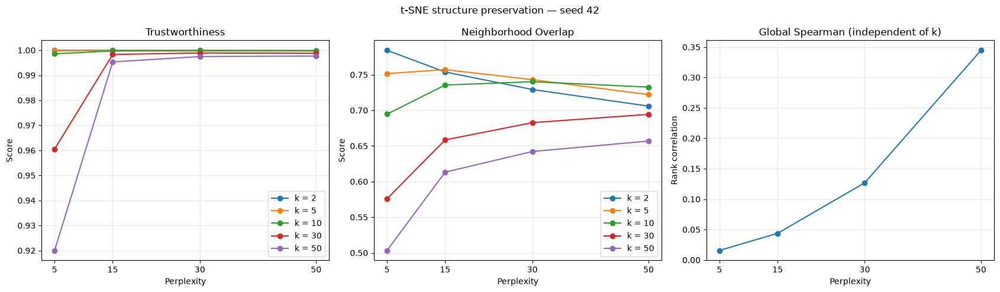

In [9]:
plot_preservation(tsne_evaluation)


**Observations**

From the results, **perplexity = 30 is a reasonable choice** for the following reasons:

- **Trustworthiness@10:** The score is approximately 1, indicating that the nearest neighbors identified in the 2D embedding generally correspond to nearby observations in the original high-dimensional space.
- **Neighborhood Overlap@10:** The score is approximately 0.74, meaning that, on average, around 74% of the 10 nearest neighbors are preserved in the 2D representation.
- **Global Spearman:** The correlation is approximately 0.13, indicating a very weak positive association between pairwise distance rankings in the original and embedded spaces. Therefore, global distance relationships are poorly preserved.
- **Comparison with perplexity = 50:** Although perplexity = 50 achieves a higher Global Spearman correlation (approximately 0.34) and slightly better neighborhood preservation for larger values of $k$, perplexity = 30 performs better for smaller neighborhoods ($k=2,5,10$).

In this sense, Perplexity = 30 is preferred because the primary objective of t-SNE is to preserve local neighborhood relationships rather than global distances. 

### **3.2.5 Seeds Stability for perplexity=30**

In [10]:
tsne_stability = SeedStability("tsne", perplexity=30, force_retrain=False).fit(data)


Seed 0: existing embedding loaded.
Seed 21: existing embedding loaded.
Seed 42: existing embedding loaded.
Seed 123: existing embedding loaded.
Seed 7: existing embedding loaded.
Seed 13: existing embedding loaded.
Seed 57: existing embedding loaded.
Seed 99: existing embedding loaded.
Seed 202: existing embedding loaded.
Seed 314: existing embedding loaded.


In [11]:
tsne_stability.run()
tsne_stability.display_matrices()



Neighborhood Stability@2


,0,21,42,123,7,13,57,99,202,314
0,1.000,0.895,0.890,0.895,0.897,0.898,0.892,0.892,0.892,0.896
21,0.895,1.000,0.891,0.886,0.893,0.899,0.891,0.889,0.895,0.896
42,0.890,0.891,1.000,0.892,0.898,0.893,0.893,0.897,0.893,0.893
123,0.895,0.886,0.892,1.000,0.899,0.895,0.889,0.890,0.889,0.893
7,0.897,0.893,0.898,0.899,1.000,0.902,0.894,0.894,0.891,0.901
13,0.898,0.899,0.893,0.895,0.902,1.000,0.893,0.895,0.897,0.902
57,0.892,0.891,0.893,0.889,0.894,0.893,1.000,0.891,0.892,0.891
99,0.892,0.889,0.897,0.890,0.894,0.895,0.891,1.000,0.891,0.907
202,0.892,0.895,0.893,0.889,0.891,0.897,0.892,0.891,1.000,0.888
314,0.896,0.896,0.893,0.893,0.901,0.902,0.891,0.907,0.888,1.000



Neighborhood Stability@5


,0,21,42,123,7,13,57,99,202,314
0,1.000,0.916,0.912,0.917,0.918,0.919,0.912,0.913,0.914,0.917
21,0.916,1.000,0.912,0.912,0.914,0.918,0.915,0.911,0.915,0.917
42,0.912,0.912,1.000,0.913,0.919,0.915,0.912,0.917,0.913,0.913
123,0.917,0.912,0.913,1.000,0.918,0.915,0.912,0.911,0.911,0.915
7,0.918,0.914,0.919,0.918,1.000,0.923,0.913,0.916,0.912,0.921
13,0.919,0.918,0.915,0.915,0.923,1.000,0.914,0.917,0.918,0.923
57,0.912,0.915,0.912,0.912,0.913,0.914,1.000,0.914,0.912,0.912
99,0.913,0.911,0.917,0.911,0.916,0.917,0.914,1.000,0.912,0.925
202,0.914,0.915,0.913,0.911,0.912,0.918,0.912,0.912,1.000,0.911
314,0.917,0.917,0.913,0.915,0.921,0.923,0.912,0.925,0.911,1.000



Neighborhood Stability@10


,0,21,42,123,7,13,57,99,202,314
0,1.000,0.920,0.916,0.922,0.923,0.923,0.916,0.917,0.918,0.920
21,0.920,1.000,0.919,0.916,0.918,0.922,0.918,0.915,0.920,0.920
42,0.916,0.919,1.000,0.918,0.922,0.918,0.915,0.920,0.917,0.918
123,0.922,0.916,0.918,1.000,0.923,0.920,0.914,0.915,0.917,0.919
7,0.923,0.918,0.922,0.923,1.000,0.925,0.917,0.920,0.916,0.924
13,0.923,0.922,0.918,0.920,0.925,1.000,0.917,0.920,0.921,0.925
57,0.916,0.918,0.915,0.914,0.917,0.917,1.000,0.915,0.916,0.914
99,0.917,0.915,0.920,0.915,0.920,0.920,0.915,1.000,0.916,0.931
202,0.918,0.920,0.917,0.917,0.916,0.921,0.916,0.916,1.000,0.914
314,0.920,0.920,0.918,0.919,0.924,0.925,0.914,0.931,0.914,1.000



Neighborhood Stability@30


,0,21,42,123,7,13,57,99,202,314
0,1.000,0.896,0.893,0.900,0.903,0.901,0.893,0.896,0.895,0.900
21,0.896,1.000,0.893,0.891,0.896,0.896,0.892,0.891,0.896,0.896
42,0.893,0.893,1.000,0.892,0.901,0.895,0.890,0.897,0.894,0.896
123,0.900,0.891,0.892,1.000,0.902,0.896,0.889,0.892,0.894,0.896
7,0.903,0.896,0.901,0.902,1.000,0.903,0.893,0.898,0.893,0.903
13,0.901,0.896,0.895,0.896,0.903,1.000,0.891,0.896,0.897,0.904
57,0.893,0.892,0.890,0.889,0.893,0.891,1.000,0.889,0.893,0.889
99,0.896,0.891,0.897,0.892,0.898,0.896,0.889,1.000,0.892,0.911
202,0.895,0.896,0.894,0.894,0.893,0.897,0.893,0.892,1.000,0.889
314,0.900,0.896,0.896,0.896,0.903,0.904,0.889,0.911,0.889,1.000



Neighborhood Stability@50


,0,21,42,123,7,13,57,99,202,314
0,1.000,0.875,0.873,0.879,0.883,0.879,0.870,0.876,0.876,0.881
21,0.875,1.000,0.874,0.869,0.877,0.876,0.872,0.871,0.876,0.877
42,0.873,0.874,1.000,0.870,0.882,0.873,0.868,0.878,0.874,0.877
123,0.879,0.869,0.870,1.000,0.885,0.874,0.866,0.871,0.874,0.875
7,0.883,0.877,0.882,0.885,1.000,0.884,0.873,0.879,0.872,0.885
13,0.879,0.876,0.873,0.874,0.884,1.000,0.867,0.873,0.876,0.886
57,0.870,0.872,0.868,0.866,0.873,0.867,1.000,0.867,0.870,0.867
99,0.876,0.871,0.878,0.871,0.879,0.873,0.867,1.000,0.872,0.894
202,0.876,0.876,0.874,0.874,0.872,0.876,0.870,0.872,1.000,0.868
314,0.881,0.877,0.877,0.875,0.885,0.886,0.867,0.894,0.868,1.000


### **3.2.6 Seed Stability Visualization**

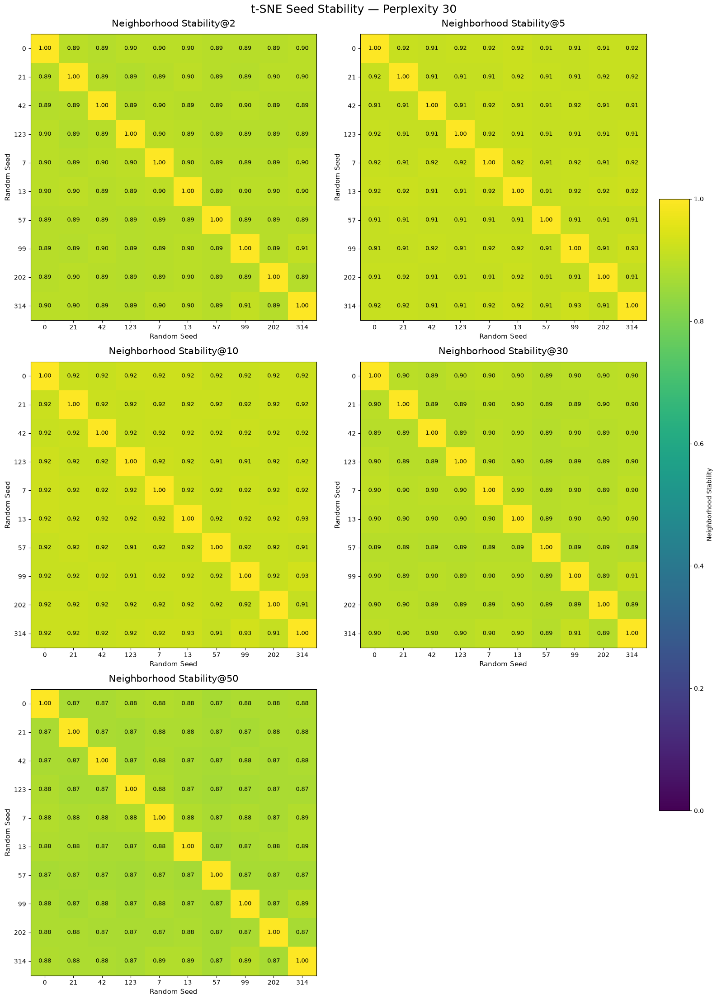

In [12]:
plot_seed_stability(tsne_stability)


**Observations — t-SNE Seed Stability**

The t-SNE embeddings generated with perplexity = 30 exhibited high neighborhood stability across 10 different random seeds.

- **Neighborhood Stability:** The stability scores were approximately 0.90 across the evaluated neighborhood sizes (k = 2, 5, 10, 30, 50), indicating that approximately 90% of nearest neighbors were consistently shared between embeddings generated with different random initializations.
- **Robustness:** These results suggest that the local neighborhood structure is largely insensitive to the random initialization of t-SNE.
- **Consistency across neighborhood sizes:** The high stability observed for both small and large neighborhoods indicates that the embedding produces consistent neighborhood relationships at multiple local scales.

**Conclusion:** These findings support the robustness of t-SNE with perplexity = 30 across random seeds. Combined with the previously observed high Trustworthiness@10 and Neighborhood Overlap@10, the results provide evidence that this configuration produces a reliable representation of local neighborhood relationships.

## **3.3 t-SNE Embedding**

### **3.3.1 t-SNE with perplexity=30**

In [13]:
tsne_final = FullEmbedding("tsne", perplexity=30, random_state=42).fit(data)


Existing t-SNE embedding loaded.
Final embedding shape: (180519, 2)
File: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/05_manifolds_tsne_umap_embeddings/tsne_final_full_dataset.csv


### **3.3.2 t-SNE Visualization**

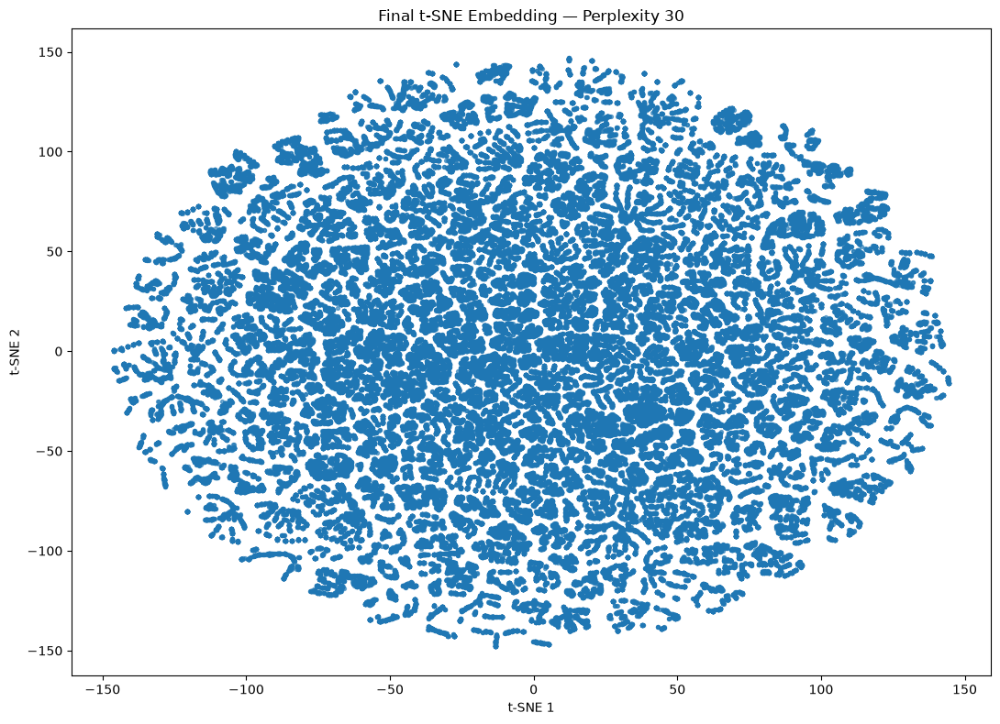

In [14]:
plot_embedding(tsne_final)


In [15]:
display(data.duplicate_summary())


Dataset shape: (180519, 10)
Total observations: 180,519
Unique feature vectors: 136,367
Duplicate observations: 44,152
Duplicate percentage: 24.46%

Groups with repeated feature vectors: 25,468
Largest duplicate group: 15

Top 10 most repeated feature combinations:


Days for shipping (real)  Days for shipment (scheduled)  Benefit per order  Sales per customer  Order Item Discount  Order Item Discount Rate  Order Item Profit Ratio  Order Item Quantity  Sales      Product Price
-0.922361                 -1.405546                      0.267587           -0.659075            0.244727             1.396461                 0.769832                 -0.775836            -0.557803  -0.080458        15
                                                         0.387090           -0.442487           -0.947887            -1.443842                 0.769832                 -0.775836            -0.557803  -0.080458        15
 0.309380                  0.777152                      0.561747           -0.125935            0.519946             0.828400                 0.769832                 -0.775836            -0.028593   0.420501        14
-0.922361                 -1.405546                      0.381057           -0.453316           -0.888257            -1.301827

**Observations — Final t-SNE Embedding Shape**

- The final t-SNE embedding exhibits an approximately circular distribution, containing numerous small, compact, and irregular local structures.
- These structures may reflect groups of observations with similar numerical characteristics. Approximately 24.46% of the observations have feature combinations that repeat another observation when considering only the 10 numerical variables used for t-SNE. However, these are not duplicate records in the complete processed dataset, since they may differ in other attributes, such as categorical variables.
- Despite the presence of localized groupings, there are no clearly separated large-scale clusters, suggesting that the embedding does not reveal an obvious global segmentation of the observations.
- The approximately circular shape should not be interpreted as an intrinsic geometric property of the original dataset, since t-SNE prioritizes local neighborhood preservation rather than global distance relationships.
- This interpretation is consistent with the previous evaluation, where the embedding achieved high local preservation metrics but a relatively low Global Spearman correlation (approximately 0.13) on the sampled data.

**Conclusion:** The t-SNE embedding reveals numerous local structures but limited interpretable global organization. Therefore, it is more appropriate for examining local similarities between marketplace transactions than for drawing conclusions about the overall geometry or separation of the dataset.

### **3.3.3 t-SNE Segmentation by Categorical Variables**

Categorical columns found: 16
['Type', 'Delivery Status', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Shipping Mode']


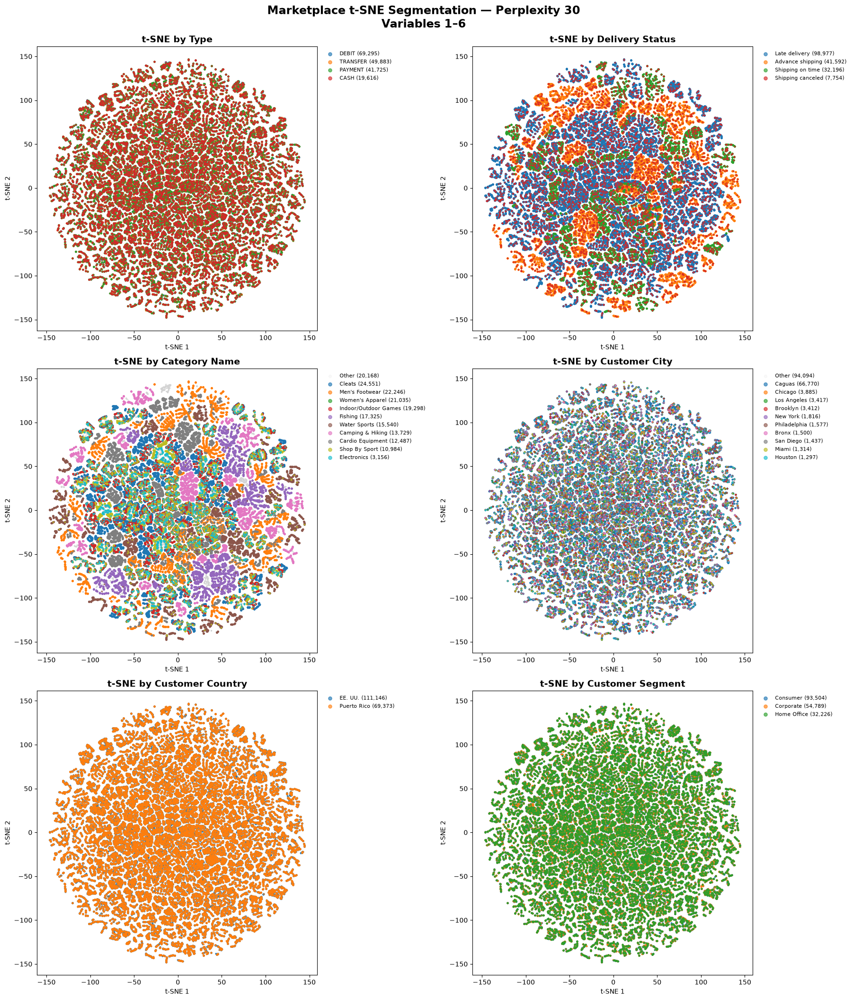

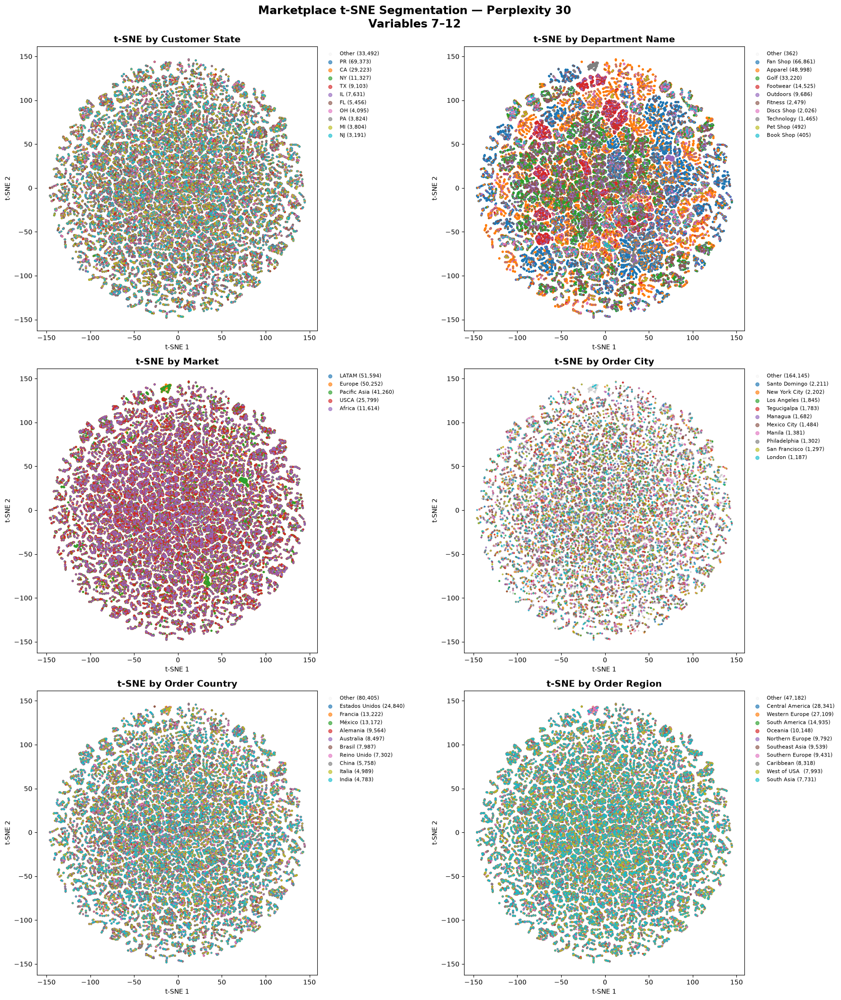

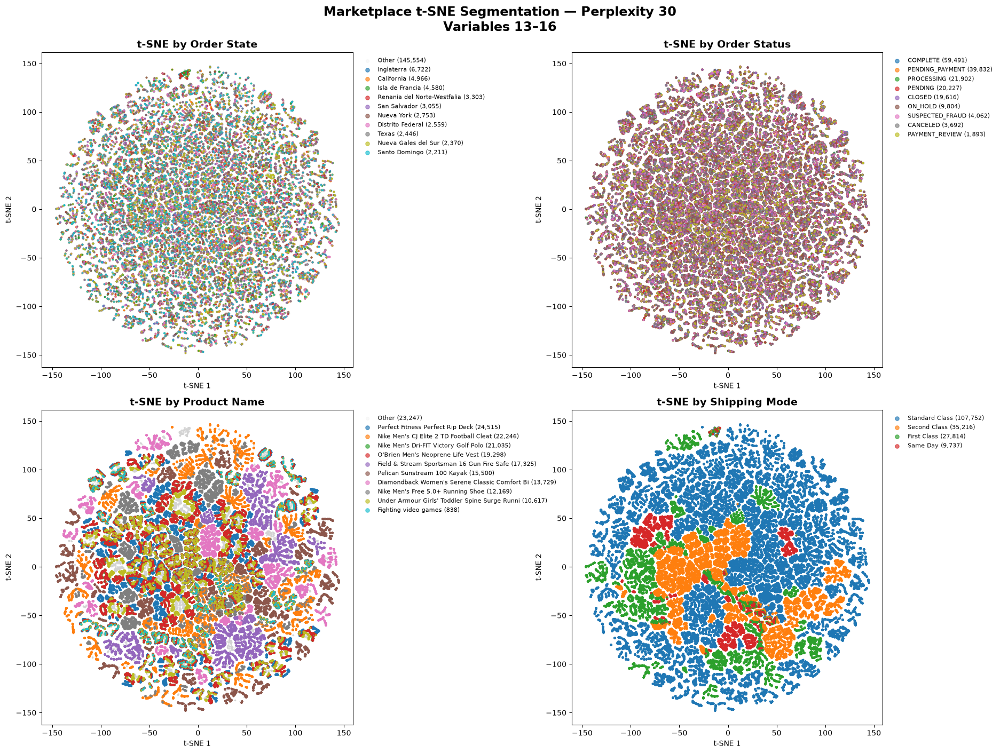

In [16]:
plot_categorical_segments(tsne_final, top_n=10)


**Observations**

- **Shipping Mode:** This variable exhibits the most noticeable visual segmentation, suggesting that orders belonging to the same shipping category tend to share similar numerical characteristics. Standard Class is the most frequent category and appears across a broader range of the embedding, indicating greater visual dispersion.
- **Product Name and Category Name:** Both variables exhibit some localized segmentation, with small groups of observations belonging to the same product or category concentrated in particular regions.
- **Department Name:** Some localized groupings are visible, although substantial overlap between categories makes the separation less evident.
- **Other categorical variables:** No clear visual separation is observed, as their categories are widely distributed and overlap throughout the embedding.

**Conclusion:** The t-SNE embedding reveals some local structures associated with Shipping Mode, Product Name, and Category Name. However, most categorical variables exhibit substantial overlap, suggesting that the selected numerical features do not produce clearly distinguishable groups for these attributes.

## **4. UMAP (Uniform Manifold Approximation and Projection)**

### **4.1 Notation**


**UMAP (Uniform Manifold Approximation and Projection)** is a nonlinear dimensionality reduction method. It builds a weighted neighborhood graph and finds a low-dimensional map that represents its connections.

**1. Notation**

- $x_i \in \mathbb{R}^{D}$: original observation.
- $y_i \in \mathbb{R}^{d}$: reduced representation, usually $d=2$.
- $N_i$: selected neighbors of $x_i$, excluding itself.
- $\rho_i$: local distance reference.
- $\sigma_i$: local scale.
- $w_{j\mid i}$: directed connection weight.
- $p_{ij}$: symmetric original-space connection.
- $q_{ij}$: reduced-space connection weight.
**2. Neighbors and Local Weights**

UMAP identifies nearby observations using a distance metric, such as Euclidean distance:

$$
d(x_i,x_j)=\sqrt{\sum_{r=1}^{D}(x_{ir}-x_{jr})^2}.
$$

n_neighbors controls the neighborhood scale: smaller values emphasize local detail; larger values consider broader relationships.

Without duplicates and with unit local connectivity, $\rho_i$ is the nearest positive neighbor distance. For $j\in N_i$:

$$
w_{j\mid i}
=
\exp\left(
-\frac{\max(0,d(x_i,x_j)-\rho_i)}{\sigma_i}
\right).
$$

Outside the neighborhood, $w_{j\mid i}=0$. UMAP adjusts $\sigma_i$ numerically to adapt connections to local distance scales.

**These weights belong to $[0,1]$ but do not need to sum to one.**

**3. Symmetric Graph**

The two directed connections are combined through a fuzzy union:

$$
p_{ij}
=
w_{j\mid i}+w_{i\mid j}
-w_{j\mid i}w_{i\mid j}.
$$

For example:

$$
w_{j\mid i}=0.6,\quad w_{i\mid j}=0.4
\quad\Rightarrow\quad
p_{ij}=0.76.
$$

This produces a symmetric weighted graph: $p_{ij}=p_{ji}$.

**4. Similarities in the Reduced Space**

UMAP defines:

$$
q_{ij}
=
\frac{1}{1+a\|y_i-y_j\|^{2b}},
\qquad i\ne j.
$$

The parameters $a,b$ are fitted using min_dist and spread. Nearby points have larger $q_{ij}$; distant points have smaller values. There is no global normalization.

**5. Objective and Optimization**

A conceptual full-pair objective is binary cross-entropy:

$$
\mathcal{L}(Y)
=
-\sum_{i<j}
\left[
p_{ij}\log(q_{ij})
+
(1-p_{ij})\log(1-q_{ij})
\right].
$$

- **Attraction:** strong original connections favor high $q_{ij}$.
- **Repulsion:** weak original connections penalize excessive closeness.

A basic update is:

$$
y_i^{(t+1)}
=
y_i^{(t)}
-\eta\nabla_{y_i}\mathcal{L}(Y^{(t)}).
$$

**$P$ remains fixed; positions $Y$ change, and $Q$ is recalculated.** In practice, UMAP uses stochastic optimization with edge sampling and negative sampling.

In UMAP each point represents an observation; nearby points suggest related feature profiles. Also, It does **not automatically discover cluster labels**, and distances between separated groups or their apparent densities should not be interpreted literally. Its **main difference from t-SNE** is that t-SNE compares normalized probabilities using KL divergence; UMAP compares fuzzy graph connections using cross-entropy.

### **4.2 Hyperparameter Sensitivity**

In [17]:
umap_search = UMAPSearch(force_retrain=False).run(data)


Loaded n_neighbors=10, min_dist=0.0. Existing file preserved.
Loaded n_neighbors=10, min_dist=0.1. Existing file preserved.
Loaded n_neighbors=10, min_dist=0.5. Existing file preserved.
Loaded n_neighbors=30, min_dist=0.0. Existing file preserved.
Loaded n_neighbors=30, min_dist=0.1. Existing file preserved.
Loaded n_neighbors=30, min_dist=0.5. Existing file preserved.
Loaded n_neighbors=50, min_dist=0.0. Existing file preserved.
Loaded n_neighbors=50, min_dist=0.1. Existing file preserved.
Loaded n_neighbors=50, min_dist=0.5. Existing file preserved.
Loaded n_neighbors=100, min_dist=0.0. Existing file preserved.
Loaded n_neighbors=100, min_dist=0.1. Existing file preserved.
Loaded n_neighbors=100, min_dist=0.5. Existing file preserved.

Total UMAP configurations: 12
Sample shape: (30000, 10)


### **4.3 Structure Preservation**

In [18]:
umap_evaluation = PreservationEvaluation(evaluation_size=30000).run(umap_search)
umap_evaluation.display()


Evaluating 30,000 observations for 12 configurations.
Progress file: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/05_manifolds_tsne_umap_embeddings/umap_preservation_metrics_eval30000_ks2-5-10-30-50_seed42_55d4f50e322d.csv
Completed metrics resume; an interrupted metric starts again.
Skipping (10, 0.0): already complete.
Skipping (10, 0.1): already complete.
Skipping (10, 0.5): already complete.
Skipping (30, 0.0): already complete.
Skipping (30, 0.1): already complete.
Skipping (30, 0.5): already complete.
Skipping (50, 0.0): already complete.
Skipping (50, 0.1): already complete.
Skipping (50, 0.5): already complete.
Skipping (100, 0.0): already complete.
Skipping (100, 0.1): already complete.
Skipping (100, 0.5): already complete.

FINAL UMAP RESULTS
 n_neighbors  min_dist  Trustworthiness@2  Neighborhood Overlap@2  Trustworthiness@5  Neighborhood Overlap@5  Trustworthiness@10  Neighborhood Overlap@10  Trustworth

,n_neighbors,min_dist,Trustworthiness@2,Neighborhood Overlap@2,Trustworthiness@5,Neighborhood Overlap@5,Trustworthiness@10,Neighborhood Overlap@10,Trustworthiness@30,Neighborhood Overlap@30,Trustworthiness@50,Neighborhood Overlap@50,Global Spearman
0,10,0.0,0.999041,0.392483,0.998794,0.537267,0.997358,0.591120,0.989631,0.562230,0.982154,0.526952,0.117179
1,10,0.1,0.998527,0.419033,0.998140,0.551273,0.996944,0.603827,0.990985,0.572224,0.983472,0.532671,0.092453
2,10,0.5,0.984273,0.308517,0.982460,0.439813,0.979475,0.510013,0.966972,0.512058,0.955248,0.487687,0.128148
3,30,0.0,0.997504,0.279500,0.997353,0.409167,0.997062,0.495313,0.996120,0.571682,0.994602,0.571827,0.320473
4,30,0.1,0.996672,0.313683,0.996426,0.438067,0.996187,0.517800,0.995029,0.585350,0.993526,0.582514,0.316223
5,30,0.5,0.987873,0.256967,0.987442,0.368987,0.986532,0.444557,0.984282,0.529214,0.982063,0.537794,0.314760
6,50,0.0,0.996889,0.236800,0.996759,0.355967,0.996478,0.446953,0.995380,0.538936,0.994231,0.555832,0.315995
7,50,0.1,0.996083,0.259767,0.995955,0.379587,0.995686,0.462403,0.994689,0.547701,0.993384,0.560742,0.336789
8,50,0.5,0.985728,0.222267,0.985130,0.326740,0.984507,0.400583,0.982442,0.488886,0.980618,0.512200,0.292599
9,100,0.0,0.995871,0.194783,0.995593,0.303607,0.995353,0.393277,0.994285,0.502170,0.993155,0.527613,0.352466


,n_neighbors,min_dist,k,Trustworthiness,Neighborhood Overlap
0,10,0.0,2,0.999041,0.392483
1,10,0.0,5,0.998794,0.537267
2,10,0.0,10,0.997358,0.591120
3,10,0.0,30,0.989631,0.562230
4,10,0.0,50,0.982154,0.526952
5,10,0.1,2,0.998527,0.419033
6,10,0.1,5,0.998140,0.551273
7,10,0.1,10,0.996944,0.603827
8,10,0.1,30,0.990985,0.572224
9,10,0.1,50,0.983472,0.532671


### **4.4 Metrics Visualization**

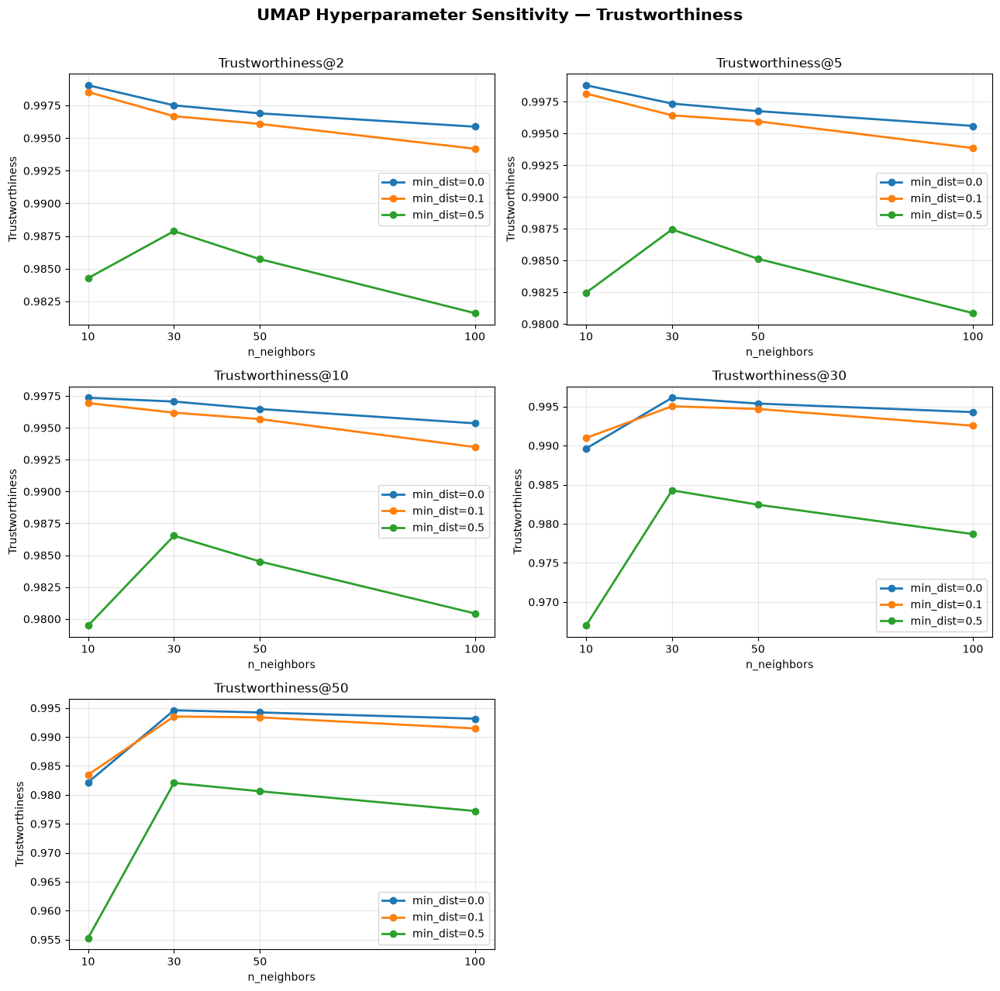

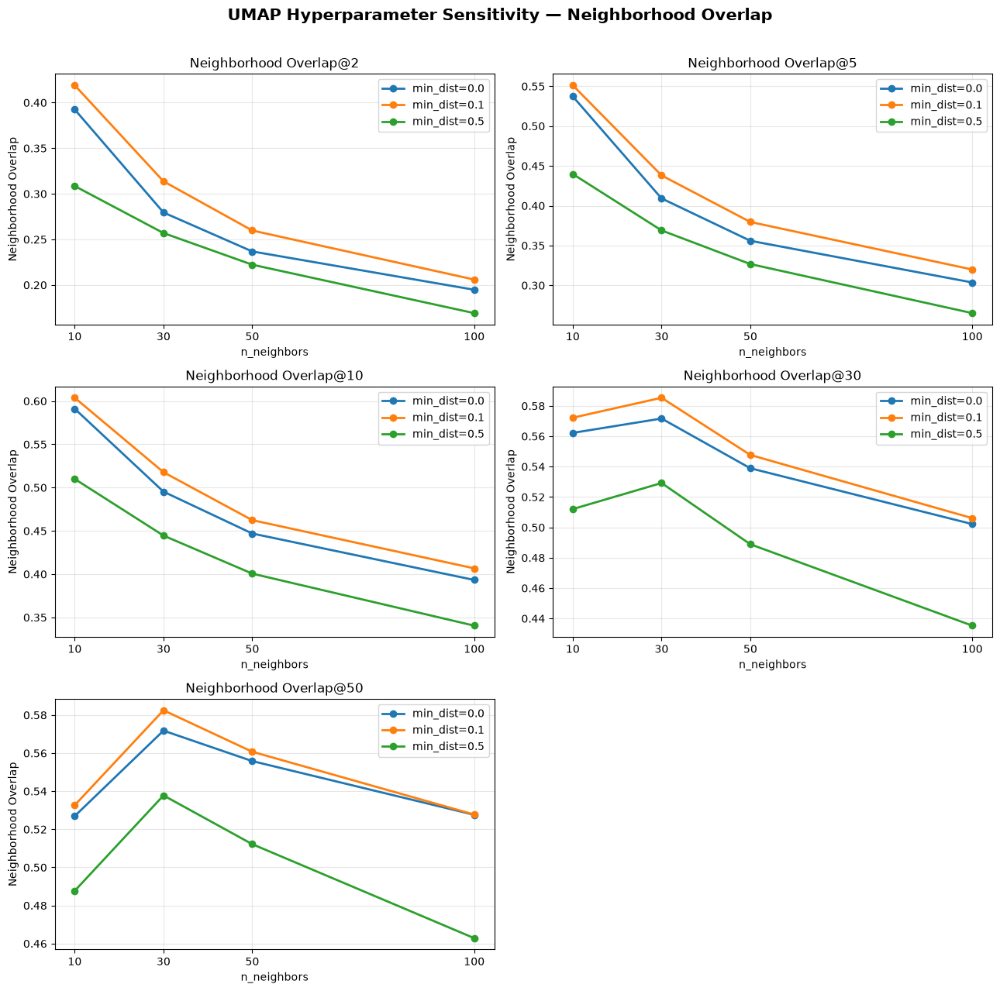

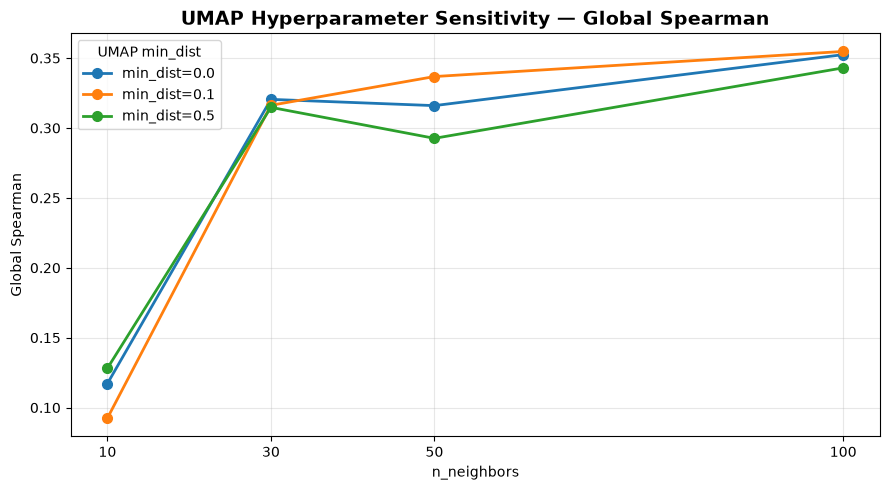

In [19]:
plot_preservation(umap_evaluation)


**Observations**

The configuration n_neighbors = 30 and min_dist = 0.1 is a reasonable choice for UMAP because:

- **Trustworthiness:** It achieves consistently high trustworthiness values (approximately 0.995–0.997), indicating that observations appearing close in the 2D embedding were generally close in the original feature space. Although min_dist = 0.0 achieves slightly higher scores, the differences are relatively small.

- **Neighborhood Overlap:** It achieves the highest Neighborhood Overlap@30 and Overlap@50 among the evaluated configurations, with approximately 58.5% and 58.2% preservation, respectively. However, configurations with n_neighbors = 10 perform better for smaller neighborhoods (k = 2, 5, 10).

- **Global Spearman:** It achieves a correlation of approximately 0.315, indicating limited but positive preservation of global distance rankings. Although n_neighbors = 100 achieves higher correlations (approximately 0.355), it presents lower neighborhood overlap.

The configuration provides a compromise between local and global structure preservation, achieving relatively high neighborhood overlap for moderately sized neighborhoods while maintaining a positive, although limited, global distance-rank correlation.

### **4.5 Seed Stability for UMAP with min_dist=0.1 and n_neighbors=30**

All ten seeds are fitted again on the same 30,000 sampled observations in the same row order. Each fit uses Euclidean distance, spectral initialization, 200 epochs, and one execution thread. Every fit builds its own neighborhood graph, so this experiment measures overall sensitivity to the random seed.

For each k in [2, 5, 10, 30, 50], stability is the mean fraction of shared nearest-neighbor observation IDs between two embeddings. Self-neighbors are excluded. This score is invariant to translation, rotation, and reflection; it measures local neighborhood agreement rather than absolute coordinate agreement or preservation of original-space distances.

The summary uses the 45 distinct seed pairs, excluding the diagonal. Pairwise standard deviation is descriptive: pairs sharing a seed are not independent. Identical or tied points can have interchangeable neighbor IDs, especially at small k, which can reduce exact-ID overlap. A separate timestamped run directory records the sample fingerprint, settings, UMAP version, embeddings, matrices, summary, and heatmaps.


In [4]:
# Set force_retrain=True to fit a new timestamped experiment.
umap_stability = SeedStability(
    "umap", n_neighbors=30, min_dist=0.1, force_retrain=False,
).fit(data)


Freshly fitted all 10 seeds on 30,000 observations.
Run: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/05_manifolds_tsne_umap_embeddings/umap_seed_stability_runs/20261113T165915_774742Z
Seed 0 completed in 63.0s.
Seed 21 completed in 27.7s.
Seed 42 completed in 30.1s.
Seed 123 completed in 27.2s.
Seed 7 completed in 27.2s.
Seed 13 completed in 27.2s.
Seed 57 completed in 27.0s.
Seed 99 completed in 26.9s.
Seed 202 completed in 27.0s.
Seed 314 completed in 26.8s.


In [5]:
umap_stability.run()
display(umap_stability.summary.round(4))


k,mean_overlap,pairwise_std,min_overlap,max_overlap,seed_pairs,random_overlap_baseline
2,0.2995,0.0086,0.2830,0.3166,45,0.0001
5,0.4619,0.0120,0.4447,0.4869,45,0.0002
10,0.5889,0.0149,0.5669,0.6196,45,0.0003
30,0.7525,0.0181,0.7241,0.7882,45,0.0010
50,0.8012,0.0198,0.7703,0.8398,45,0.0017


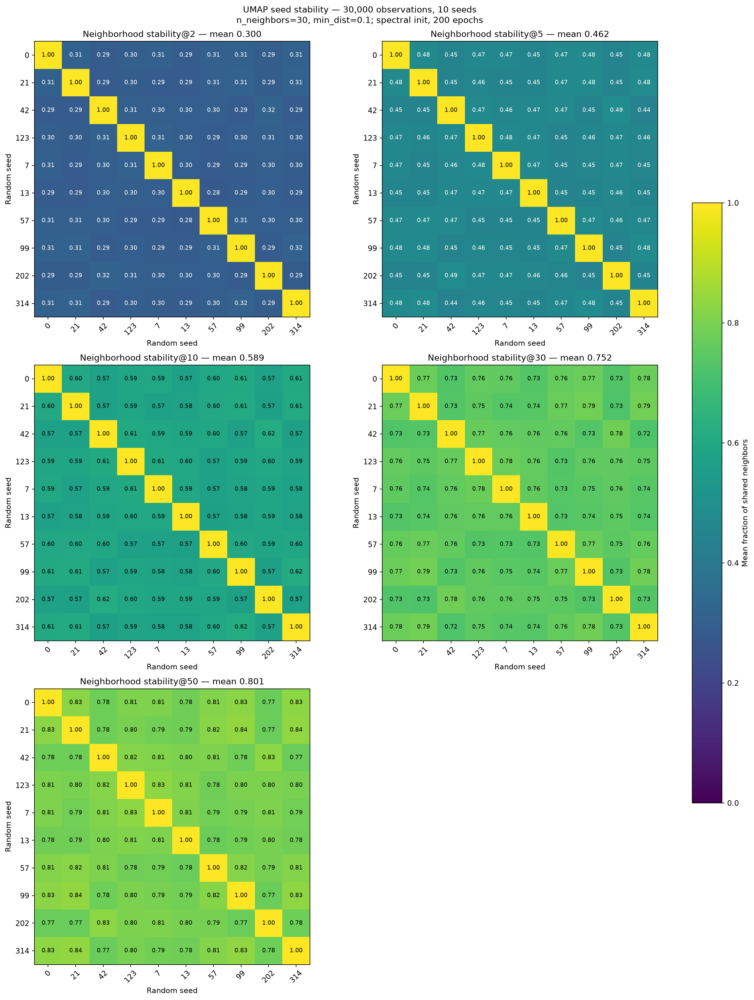

Heatmaps saved: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/05_manifolds_tsne_umap_embeddings/umap_seed_stability_runs/20261113T165915_774742Z/heatmaps.png


In [6]:
plot_seed_stability(umap_stability)


**Observations**

The UMAP embeddings generated with min_dist = 0.1 and n_neighbors = 30 exhibited different levels of neighborhood stability across 10 random seeds.

- **Neighborhood Stability:** The mean stability scores were below 0.5 for the smallest evaluated neighborhoods (k = 2 and k = 5), with values of 0.300 and 0.462, respectively. This indicates that only 30% and 46.2% of the nearest neighbors were shared, on average, between embeddings generated with different random seeds. However, larger neighborhoods exhibited higher stability, with mean scores of 0.589, 0.752, and 0.801 for k = 10, 30, 50, respectively. Therefore, neighborhood stability increased with the evaluation neighborhood size.

- **Robustness:** These results suggest that UMAP is sensitive to random initialization when preserving the exact closest neighbors, particularly for k = 2 and k = 5. However, the broader neighborhood structures are more consistent across random seeds, especially for k = 30 and k = 50. This indicates that UMAP provides relatively reproducible representations of larger local neighborhoods, although the identities of the nearest neighbors may vary between runs.

Overall, the selected configuration demonstrates greater stability for broader neighborhood structures than for very small neighborhoods, suggesting that its interpretation should prioritize general similarity patterns rather than exact nearest-neighbor relationships.

## **4.3 Implementation of UMAP**

### **4.3.1 UMAP with n_neighbours=30 and min_dist=0.1**

In [25]:
umap_final = FullEmbedding("umap", n_neighbors=30, min_dist=0.1, random_state=42).fit(data)


/home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/env/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/env/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Final UMAP embedding computed and saved.
Final embedding shape: (180519, 2)
File: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/05_manifolds_tsne_umap_embeddings/umap_final_full_dataset.csv


### **4.3.2 UMAP Visualization**

Embedding shape: (180519, 2)


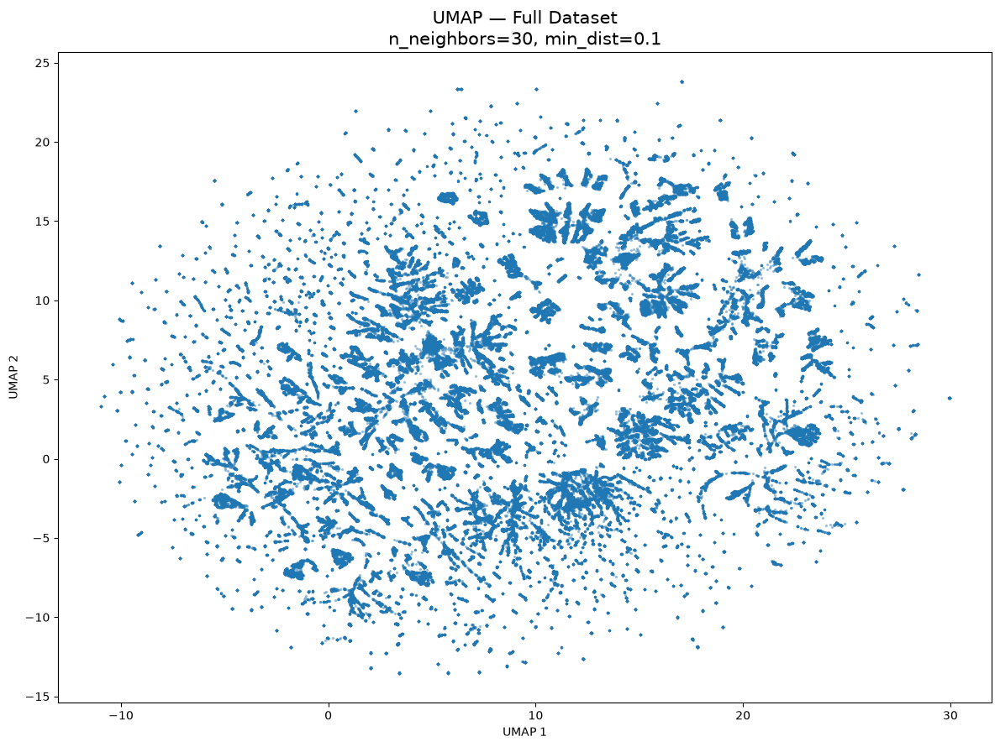

Plot saved to: /home/joel-felipe-alba-acosta/Documents/UNIVERSITY/2026-2/APRENDIZAJE_NO_SUPERVISADO/Corte_3/PROYECTO_FINAL/results/05_manifolds_tsne_umap_embeddings/umap_final_full_dataset.png


In [28]:
plot_embedding(umap_final)


### **4.3.3 UMAP Segmentation by Categorical Variables**

UMAP embedding shape: (180519, 2)
Categorical columns found: 16
['Type', 'Delivery Status', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order City', 'Order Country', 'Order Region', 'Order State', 'Order Status', 'Product Name', 'Shipping Mode']


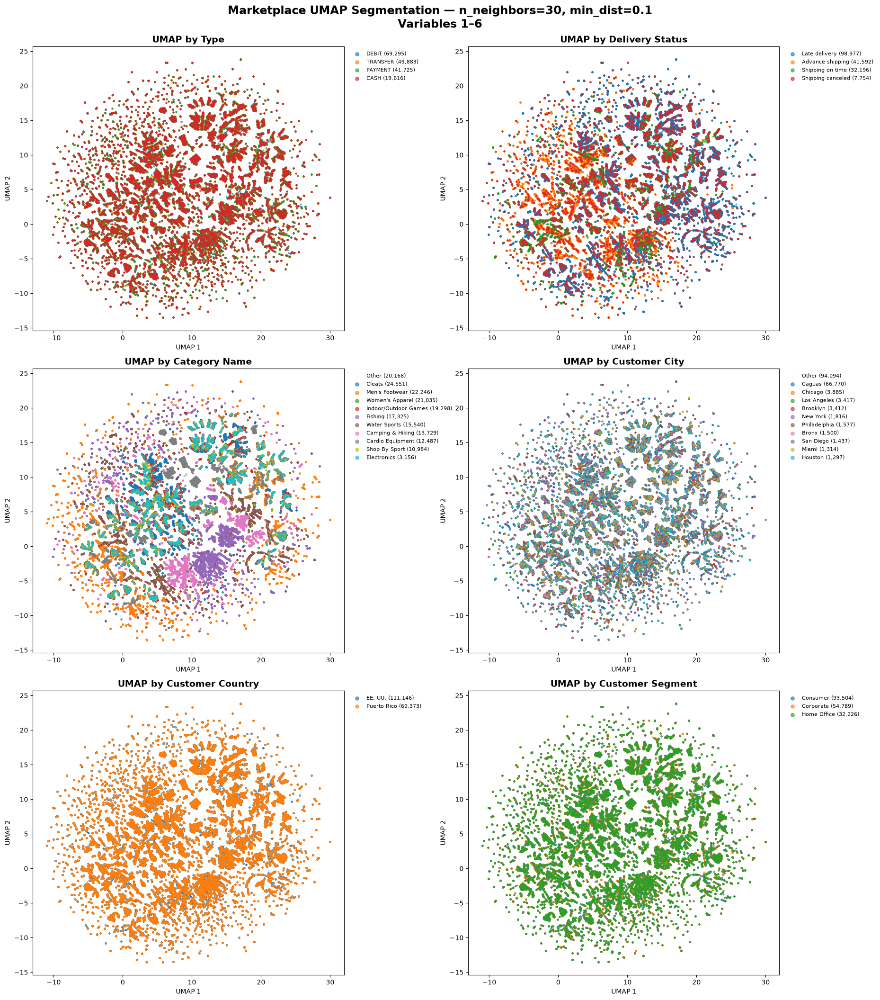

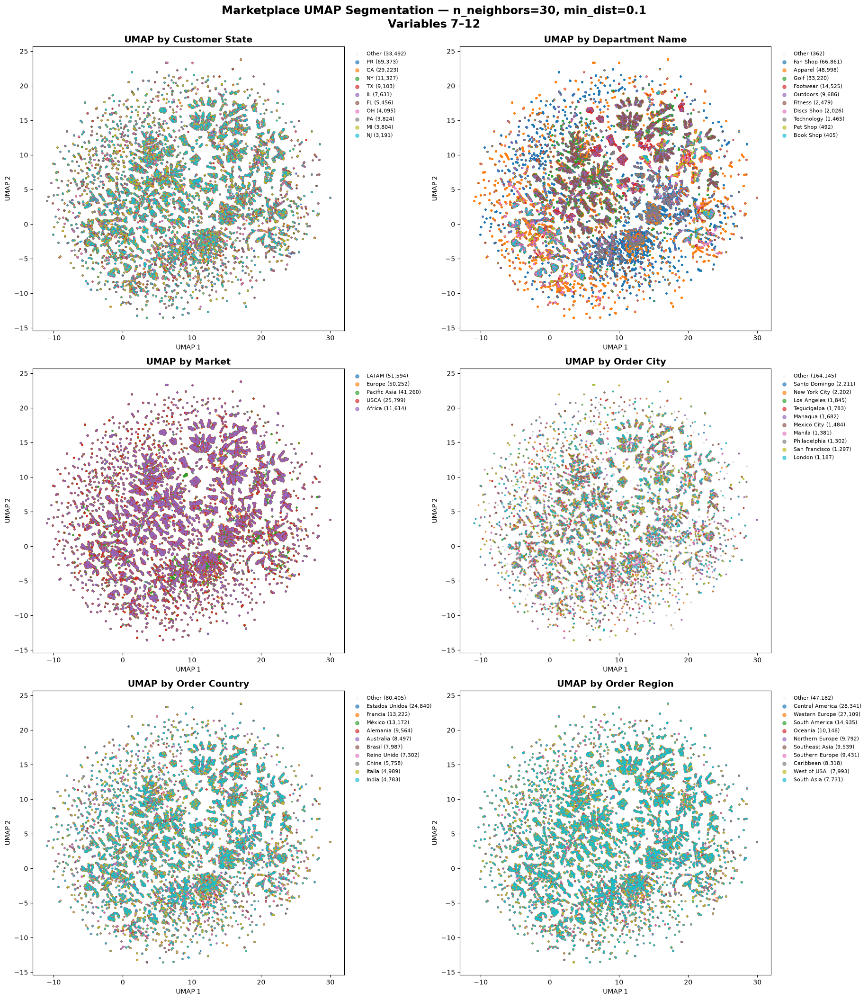

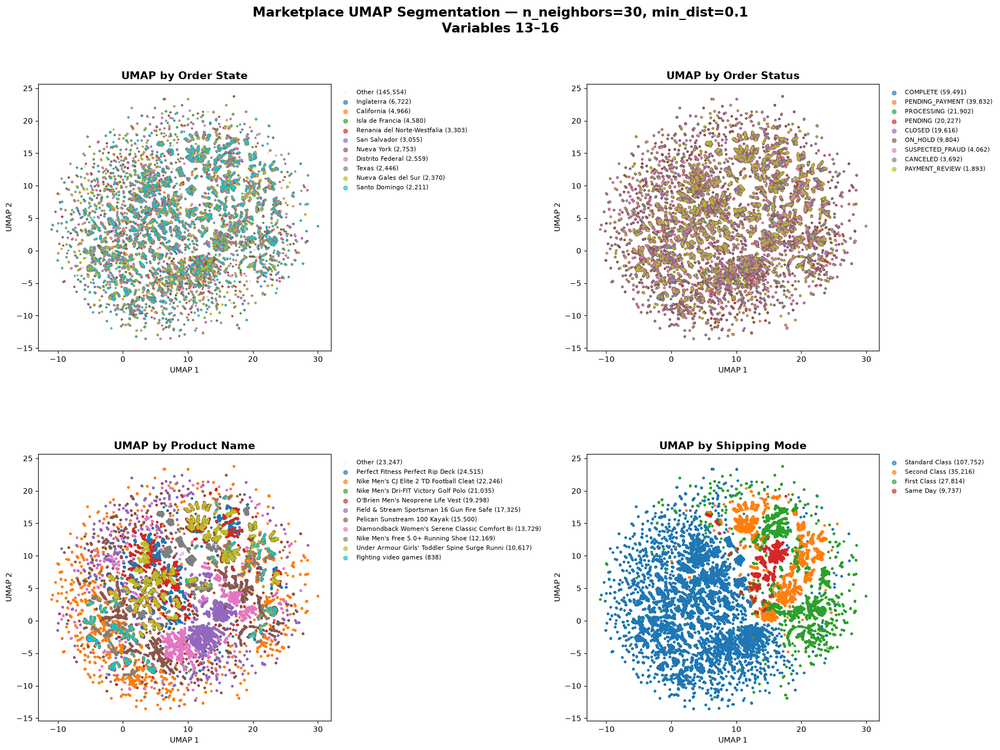

In [30]:
plot_categorical_segments(umap_final, top_n=10)


**Observations**

- **Shipping Mode:** The segmentation shows relatively clear spatial differentiation between shipping modes. Standard Class observations are predominantly concentrated in the left and lower regions of the embedding, while Same Day orders form a more compact group in the upper-right region. First Class and Second Class tend to occupy several distinct regions rather than forming a single cluster for each category. This suggests that shipping mode is associated with some of the numerical patterns captured by UMAP.

- **Product Name and Category Name:** Both variables exhibit several localized concentrations across the embedding. Certain products, such as *Diamondback Women's Serene Classic Comfort Bike* and *Field & Stream Sportsman 16 Gun Fire Safe*, appear in relatively well-defined regions. However, other products are distributed across multiple smaller groups. Category Name exhibits similar behavior, suggesting that transactions involving similar product categories may share numerical characteristics, although the categories are not completely separated.

- **Delivery Status:** Most delivery-status categories overlap considerably throughout the embedding, indicating limited overall separation. However, Advance Shipping observations appear somewhat more concentrated toward the left-central region. This suggests that delivery status may be associated with certain numerical transaction characteristics, although it does not produce clearly distinguishable groups across the entire embedding.

## **5. Bias and Interpretability**

**Possible Sources of Bias**

Several sources of bias may influence the embeddings generated by the implemented methods. One potential source is **feature selection**, since the resulting embeddings depend on the variables included in the analysis and may change if features are added or removed. Additionally, some variables, such as Sales and Sales per customer, may contain overlapping information due to their correlation, potentially giving certain characteristics greater influence on the similarity calculations.

Another limitation concerns **sampling and hyperparameter selection**. The hyperparameters were evaluated using a sample of 30,000 transactions rather than the complete dataset, so the selected configurations may not perform identically when applied to all observations. Furthermore, the explored hyperparameter combinations were limited, meaning that other configurations could potentially produce better embeddings.

Finally, both methods were evaluated using **Euclidean distance**, which influences how similarities between observations are calculated. Choosing a different distance metric could produce different neighborhood structures and, consequently, different embeddings. Both algorithms also emphasize local relationships, which may introduce distortions in the representation of global structures.

**Interpretability**

The embeddings demonstrated strong local structure preservation according to the quantitative evaluation metrics. Both methods achieved Trustworthiness scores close to 1, indicating that observations appearing as neighbors in the embedded space generally corresponded to observations with high proximity ranks in the original space. However, **t-SNE achieved higher Neighborhood Overlap**, indicating better preservation of exact nearest-neighbor relationships under the evaluated configurations.

In contrast, **UMAP achieved a higher Global Spearman correlation**, suggesting that it better preserved the relative ordering of distances between observations. Nevertheless, its correlation remained relatively low (approximately 0.316), indicating that the global distance structure was not strongly preserved.

Furthermore, the two-dimensional embeddings allowed us to explore possible associations between numerical transaction characteristics and categorical variables. Variables such as Shipping Mode, Product Name, and Category Name exhibited some visually distinguishable patterns, while Department Name and Delivery Status showed more overlapping distributions. These observations suggest that certain transaction characteristics may be associated with the numerical relationships captured by the embeddings.

Such patterns could support further exploratory analysis related to pricing, marketing, product segmentation, and promotional strategies. However, the visual separation of observations does not necessarily demonstrate the existence of distinct groups in the original feature space. Additionally, the embedding axes do not have direct interpretations, and distances between visually separated groups should not be treated as exact representations of the original distances.